In [1]:
# Instalación de las librerías necesarias para el proyecto

!pip -q install pandas scikit-learn spacy matplotlib seaborn
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 31.1 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import pandas as pd
import sklearn
import spacy
import matplotlib
import seaborn as sns

nlp = spacy.load("en_core_web_sm")

print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("spaCy:", spacy.__version__)
print("Modelo de inglés:", nlp.meta["name"], nlp.meta["version"])
print("Entorno listo para trabajar.")

Pandas: 2.2.3
Scikit-learn: 1.6.1
spaCy: 3.8.16
Modelo de inglés: core_web_sm 3.8.0
Entorno listo para trabajar.


In [3]:
from pathlib import Path
import pandas as pd

# Archivos de datos requeridos por la preentrega
archivo_train = Path("ag_news_train.csv")
archivo_test = Path("ag_news_test.csv")

print("Directorio de trabajo:", Path.cwd())
print("CSV de entrenamiento disponible:", archivo_train.exists())
print("CSV de prueba disponible:", archivo_test.exists())

Directorio de trabajo: /content
CSV de entrenamiento disponible: False
CSV de prueba disponible: False


In [4]:
from google.colab import files

archivos_subidos = files.upload()

Saving ag_news_train.csv to ag_news_train.csv
Saving ag_news_test.csv to ag_news_test.csv


In [5]:
from pathlib import Path
import pandas as pd

archivo_train = Path("/content/ag_news_train.csv")
archivo_test = Path("/content/ag_news_test.csv")

print("Entrenamiento encontrado:", archivo_train.exists())
print("Prueba encontrada:", archivo_test.exists())

if archivo_train.exists() and archivo_test.exists():
    train_df = pd.read_csv(archivo_train)
    test_df = pd.read_csv(archivo_test)

    print("\nDimensiones de entrenamiento:", train_df.shape)
    print("Columnas de entrenamiento:", train_df.columns.tolist())

    print("\nDimensiones de prueba:", test_df.shape)
    print("Columnas de prueba:", test_df.columns.tolist())

    display(train_df.head(3))
    display(test_df.head(3))

Entrenamiento encontrado: True
Prueba encontrada: True

Dimensiones de entrenamiento: (8000, 2)
Columnas de entrenamiento: ['text', 'label']

Dimensiones de prueba: (2000, 2)
Columnas de prueba: ['text', 'label']


,text,label
0,"Red Hat Appoints New CFO. September 2, 2004 --...",Sci_Tech
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",Sci_Tech
2,Radio Outage Grounds West Coast Flights. Airpo...,Business


,text,label
0,BSkyB sees profits rise after strong subscribe...,World
1,Before-the Bell; Rouse Co. Shares Jump. &lt;A ...,Business
2,"Minutemen KO'd by Dukes. HARRISONBURG, Va. -- ...",Sports


In [6]:
# Validación inicial de los conjuntos de entrenamiento y prueba

for nombre, df in [("Entrenamiento", train_df), ("Prueba", test_df)]:
    print(f"\n{'=' * 45}")
    print(f"CONJUNTO DE {nombre.upper()}")
    print(f"{'=' * 45}")

    print("Cantidad de filas:", len(df))
    print("Valores vacíos por columna:")
    print(df[["text", "label"]].isna().sum())

    print("\nCantidad de noticias por categoría:")
    print(df["label"].value_counts().sort_index())

    print("\nCantidad de textos duplicados:", df["text"].duplicated().sum())

# Verificar que ambos conjuntos contengan las mismas categorías
categorias_train = set(train_df["label"].dropna().unique())
categorias_test = set(test_df["label"].dropna().unique())

print("\n¿Las categorías coinciden entre entrenamiento y prueba?:",
      categorias_train == categorias_test)

print("Categorías detectadas:", sorted(categorias_train))


CONJUNTO DE ENTRENAMIENTO
Cantidad de filas: 8000
Valores vacíos por columna:
text     0
label    0
dtype: int64

Cantidad de noticias por categoría:
label
Business    2000
Sci_Tech    2000
Sports      2000
World       2000
Name: count, dtype: int64

Cantidad de textos duplicados: 0

CONJUNTO DE PRUEBA
Cantidad de filas: 2000
Valores vacíos por columna:
text     0
label    0
dtype: int64

Cantidad de noticias por categoría:
label
Business    500
Sci_Tech    500
Sports      500
World       500
Name: count, dtype: int64

Cantidad de textos duplicados: 0

¿Las categorías coinciden entre entrenamiento y prueba?: True
Categorías detectadas: ['Business', 'Sci_Tech', 'Sports', 'World']


In [7]:
import html
import re
import spacy

# Cargar el modelo de inglés para la lematización
nlp = spacy.load("en_core_web_sm")

def clean_text(text):
    """Limpia y normaliza el texto de una noticia."""
    if pd.isna(text):
        return ""

    text = str(text)

    # Decodificar entidades HTML, incluso si están codificadas más de una vez
    for _ in range(2):
        text = html.unescape(text)

    # Corregir restos frecuentes de entidades HTML
    text = re.sub(r"#39;?", "'", text, flags=re.IGNORECASE)

    # Eliminar saltos de línea y etiquetas HTML
    text = re.sub(r"\\(?:[rn]|t)", " ", text)
    text = re.sub(r"[\r\n\t]+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)

    # Eliminar URLs y direcciones de correo
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)

    # Normalizar residuos de algunas entidades HTML
    text = re.sub(r"\b39\s+([st])\b", r"'\1", text, flags=re.IGNORECASE)
    text = re.sub(r"\bquot\b|\bamp\b", " ", text, flags=re.IGNORECASE)

    # Convertir a minúsculas y conservar letras, números y apóstrofos
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+'([st])\b", r"'\1", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


def lemmatize_text(text, remove_stopwords=False):
    """Lematiza el texto y permite excluir stopwords."""
    doc = nlp(text)
    tokens = []

    for token in doc:
        if token.is_space or token.is_punct:
            continue

        lemma = token.lemma_.lower().strip()

        if not lemma:
            continue

        if remove_stopwords and token.is_stop:
            continue

        tokens.append(lemma)

    return " ".join(tokens)


# Comprobar las funciones con una noticia de ejemplo
ejemplo = "The companies announced new products &amp; improved their services."

texto_limpio = clean_text(ejemplo)
texto_lematizado = lemmatize_text(texto_limpio)

print("Texto original:")
print(ejemplo)

print("\nTexto limpio:")
print(texto_limpio)

print("\nTexto lematizado:")
print(texto_lematizado)

Texto original:
The companies announced new products &amp; improved their services.

Texto limpio:
the companies announced new products improved their services

Texto lematizado:
the company announce new product improve their service


In [8]:
from tqdm.auto import tqdm

def process_corpus(texts, batch_size=128):
    """Limpia y lematiza una colección de noticias."""
    textos_limpios = [clean_text(text) for text in texts]

    lemas = []
    lemas_sin_stopwords = []

    for doc in tqdm(
        nlp.pipe(textos_limpios, batch_size=batch_size),
        total=len(textos_limpios),
        desc="Procesando noticias"
    ):
        tokens = []
        tokens_sin_stopwords = []

        for token in doc:
            if token.is_space or token.is_punct:
                continue

            lema = token.lemma_.lower().strip()

            if not lema:
                continue

            tokens.append(lema)

            if not token.is_stop:
                tokens_sin_stopwords.append(lema)

        lemas.append(" ".join(tokens))
        lemas_sin_stopwords.append(" ".join(tokens_sin_stopwords))

    return pd.DataFrame({
        "text_clean": textos_limpios,
        "text_lemmas": lemas,
        "text_lemmas_no_stop": lemas_sin_stopwords
    })


# Procesar ambos conjuntos con las mismas funciones
train_processed = process_corpus(train_df["text"])
test_processed = process_corpus(test_df["text"])

# Integrar los textos procesados sin modificar los CSV originales
train_data = pd.concat(
    [train_df.reset_index(drop=True), train_processed],
    axis=1
)

test_data = pd.concat(
    [test_df.reset_index(drop=True), test_processed],
    axis=1
)

print("Dimensiones de entrenamiento:", train_data.shape)
print("Dimensiones de prueba:", test_data.shape)

print("\nColumnas disponibles:")
print(train_data.columns.tolist())

print("\nEjemplos procesados:")
display(
    train_data[
        ["label", "text", "text_clean", "text_lemmas", "text_lemmas_no_stop"]
    ].head(3)
)

print("\nValores vacíos en los textos lematizados:")
print("Entrenamiento:", train_data["text_lemmas"].eq("").sum())
print("Prueba:", test_data["text_lemmas"].eq("").sum())

Procesando noticias:   0%|          | 0/8000 [00:00<?, ?it/s]

Procesando noticias:   0%|          | 0/2000 [00:00<?, ?it/s]

Dimensiones de entrenamiento: (8000, 5)
Dimensiones de prueba: (2000, 5)

Columnas disponibles:
['text', 'label', 'text_clean', 'text_lemmas', 'text_lemmas_no_stop']

Ejemplos procesados:


,label,text,text_clean,text_lemmas,text_lemmas_no_stop
0,Sci_Tech,"Red Hat Appoints New CFO. September 2, 2004 --...",red hat appoints new cfo september 2 2004 web ...,red hat appoint new cfo september 2 2004 web h...,red hat appoint new cfo september 2 2004 web h...
1,Sci_Tech,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",sprint sbc in hotspot roaming deal sprint and ...,sprint sbc in hotspot roam deal sprint and sbc...,sprint sbc hotspot roam deal sprint sbc commun...
2,Business,Radio Outage Grounds West Coast Flights. Airpo...,radio outage grounds west coast flights airpor...,radio outage ground west coast flights airport...,radio outage ground west coast flights airport...



Valores vacíos en los textos lematizados:
Entrenamiento: 0
Prueba: 0


In [9]:
# Experimentación con TF-IDF y Regresión Logística
# La selección de parámetros se realiza usando solo el conjunto de entrenamiento.
# El conjunto de prueba no se utiliza en esta etapa.

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Separar una parte del entrenamiento para validar configuraciones
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    train_data["text_lemmas"],
    train_data["label"],
    test_size=0.20,
    random_state=42,
    stratify=train_data["label"]
)

# Configuraciones solicitadas en la consigna
configuraciones = [
    {"max_features": 5000, "ngram_range": (1, 1)},
    {"max_features": 10000, "ngram_range": (1, 1)},
    {"max_features": 20000, "ngram_range": (1, 1)},
    {"max_features": 5000, "ngram_range": (1, 2)},
    {"max_features": 10000, "ngram_range": (1, 2)},
    {"max_features": 20000, "ngram_range": (1, 2)}
]

resultados = []

for config in configuraciones:
    vectorizador = TfidfVectorizer(
        max_features=config["max_features"],
        ngram_range=config["ngram_range"],
        min_df=2,
        sublinear_tf=True
    )

    # Ajustar el vocabulario exclusivamente con la parte de entrenamiento
    X_sub_tfidf = vectorizador.fit_transform(X_train_sub)
    X_val_tfidf = vectorizador.transform(X_val)

    modelo = LogisticRegression(max_iter=1000, random_state=42)
    modelo.fit(X_sub_tfidf, y_train_sub)

    predicciones = modelo.predict(X_val_tfidf)

    resultados.append({
        "max_features": config["max_features"],
        "ngram_range": str(config["ngram_range"]),
        "caracteristicas_reales": X_sub_tfidf.shape[1],
        "accuracy": accuracy_score(y_val, predicciones),
        "f1_macro": f1_score(y_val, predicciones, average="macro")
    })

resultados_tfidf = pd.DataFrame(resultados).sort_values(
    by=["f1_macro", "accuracy"],
    ascending=False
).reset_index(drop=True)

display(
    resultados_tfidf.style.format({
        "accuracy": "{:.4f}",
        "f1_macro": "{:.4f}"
    })
)

mejor_configuracion = resultados_tfidf.iloc[0]

print("Configuración seleccionada usando validación:")
print("max_features:", int(mejor_configuracion["max_features"]))
print("ngram_range:", mejor_configuracion["ngram_range"])
print("F1 macro de validación:", round(mejor_configuracion["f1_macro"], 4))
print("Accuracy de validación:", round(mejor_configuracion["accuracy"], 4))

,max_features,ngram_range,caracteristicas_reales,accuracy,f1_macro
0,10000,"(1, 1)",8610,0.8925,0.8920
1,20000,"(1, 1)",8610,0.8925,0.8920
2,5000,"(1, 1)",5000,0.8900,0.8895
3,10000,"(1, 2)",10000,0.8831,0.8825
4,20000,"(1, 2)",20000,0.8831,0.8824
5,5000,"(1, 2)",5000,0.8812,0.8806


Configuración seleccionada usando validación:
max_features: 10000
ngram_range: (1, 1)
F1 macro de validación: 0.892
Accuracy de validación: 0.8925


RESULTADOS FINALES EN EL CONJUNTO DE PRUEBA
Accuracy: 0.8830
Características TF-IDF: 9690
Matriz de entrenamiento: (8000, 9690)
Matriz de prueba: (2000, 9690)

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

    Business     0.8446    0.8480    0.8463       500
    Sci_Tech     0.8594    0.8560    0.8577       500
      Sports     0.9284    0.9600    0.9440       500
       World     0.8986    0.8680    0.8830       500

    accuracy                         0.8830      2000
   macro avg     0.8828    0.8830    0.8827      2000
weighted avg     0.8828    0.8830    0.8827      2000



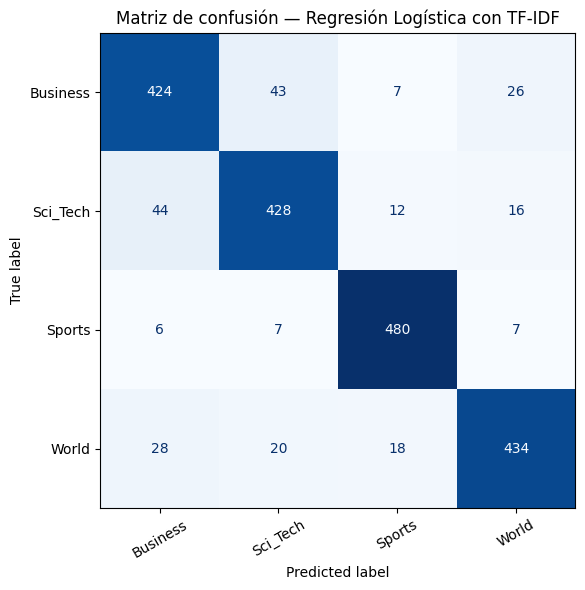

In [10]:
# Entrenamiento final y evaluación sobre el conjunto de prueba
# El vectorizador se ajusta únicamente con entrenamiento.

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)
import matplotlib.pyplot as plt

# Configuración elegida a partir de la validación
vectorizador_final = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 1),
    min_df=2,
    sublinear_tf=True
)

# fit_transform solo sobre el entrenamiento completo
X_train_tfidf = vectorizador_final.fit_transform(train_data["text_lemmas"])

# transform sobre prueba, sin volver a ajustar el vocabulario
X_test_tfidf = vectorizador_final.transform(test_data["text_lemmas"])

# Entrenar el clasificador seleccionado
modelo_final = LogisticRegression(
    max_iter=1000,
    random_state=42
)

modelo_final.fit(X_train_tfidf, train_data["label"])

# Predicciones sobre el conjunto de prueba
y_test = test_data["label"]
y_pred = modelo_final.predict(X_test_tfidf)

# Métricas generales
print("RESULTADOS FINALES EN EL CONJUNTO DE PRUEBA")
print("=" * 50)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Características TF-IDF: {X_train_tfidf.shape[1]}")
print(f"Matriz de entrenamiento: {X_train_tfidf.shape}")
print(f"Matriz de prueba: {X_test_tfidf.shape}")

# Reporte por categoría
print("\nREPORTE DE CLASIFICACIÓN")
print("=" * 50)
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

# Matriz de confusión multiclase
etiquetas = sorted(train_data["label"].unique())
matriz = confusion_matrix(y_test, y_pred, labels=etiquetas)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=etiquetas
)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Matriz de confusión — Regresión Logística con TF-IDF")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [11]:
# Análisis de las confusiones entre categorías

import pandas as pd
import numpy as np

matriz_df = pd.DataFrame(
    matriz,
    index=[f"Real: {etiqueta}" for etiqueta in etiquetas],
    columns=[f"Predicho: {etiqueta}" for etiqueta in etiquetas]
)

display(matriz_df)

# Errores por categoría real
errores_por_categoria = []

for i, etiqueta in enumerate(etiquetas):
    correctas = matriz[i, i]
    total = matriz[i].sum()
    errores = total - correctas

    errores_por_categoria.append({
        "categoría": etiqueta,
        "clasificadas_correctamente": int(correctas),
        "clasificadas_incorrectamente": int(errores),
        "total": int(total),
        "porcentaje_error": errores / total
    })

errores_df = pd.DataFrame(errores_por_categoria)
errores_df = errores_df.sort_values(
    "porcentaje_error",
    ascending=False
)

print("Errores por categoría:")
display(
    errores_df.style.format({
        "porcentaje_error": "{:.2%}"
    })
)

# Pares de categorías que más se confunden entre sí
confusiones = []

for i in range(len(etiquetas)):
    for j in range(len(etiquetas)):
        if i != j and matriz[i, j] > 0:
            confusiones.append({
                "categoría_real": etiquetas[i],
                "categoría_predicha": etiquetas[j],
                "cantidad": int(matriz[i, j])
            })

confusiones_df = pd.DataFrame(confusiones).sort_values(
    "cantidad",
    ascending=False
)

print("Confusiones más frecuentes:")
display(confusiones_df.head(10))

,Predicho: Business,Predicho: Sci_Tech,Predicho: Sports,Predicho: World
Real: Business,424,43,7,26
Real: Sci_Tech,44,428,12,16
Real: Sports,6,7,480,7
Real: World,28,20,18,434


Errores por categoría:


,categoría,clasificadas_correctamente,clasificadas_incorrectamente,total,porcentaje_error
0,Business,424,76,500,15.20%
1,Sci_Tech,428,72,500,14.40%
3,World,434,66,500,13.20%
2,Sports,480,20,500,4.00%


Confusiones más frecuentes:


,categoría_real,categoría_predicha,cantidad
3,Sci_Tech,Business,44
0,Business,Sci_Tech,43
9,World,Business,28
2,Business,World,26
10,World,Sci_Tech,20
11,World,Sports,18
5,Sci_Tech,World,16
4,Sci_Tech,Sports,12
1,Business,Sports,7
7,Sports,Sci_Tech,7


In [12]:
# Registrar las versiones de las librerías utilizadas en el proyecto

import pandas as pd
import sklearn
import spacy
import matplotlib
import seaborn
import sys

versiones = {
    "Python": sys.version.split()[0],
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "spacy": spacy.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": seaborn.__version__,
    "modelo_spacy_en": nlp.meta["version"]
}

for libreria, version in versiones.items():
    print(f"{libreria}: {version}")

Python: 3.13.16
pandas: 2.2.3
scikit-learn: 1.6.1
spacy: 3.8.16
matplotlib: 3.10.0
seaborn: 0.13.2
modelo_spacy_en: 3.8.0


In [13]:
from pathlib import Path

# Crear la documentación del proyecto
readme = r"""
# Clasificador Supervisado de Noticias con TF-IDF

## Descripción

Proyecto de clasificación supervisada de noticias de AG News en cuatro categorías:
Business, Sci_Tech, Sports y World.

La solución utiliza preprocesamiento de texto, lematización, vectorización TF-IDF
y Regresión Logística para predecir la categoría de cada noticia.

## Dataset

Se utilizaron los archivos del Módulo 2:

- `ag_news_train.csv`: 8.000 noticias.
- `ag_news_test.csv`: 2.000 noticias.

Ambos archivos contienen las columnas `text` y `label`. Las cuatro categorías
están representadas de forma equilibrada en ambos conjuntos.

## Preprocesamiento

El texto se normaliza convirtiéndolo a minúsculas, decodificando entidades HTML,
eliminando etiquetas HTML, URLs, correos electrónicos y caracteres no relevantes.
Luego se utiliza spaCy para lematizar los tokens.

Se conservaron las etiquetas originales del dataset.

## Experimentación con TF-IDF

Se compararon seis configuraciones usando una división interna del conjunto de
entrenamiento. La selección se realizó según F1 macro, utilizando accuracy como
criterio secundario.

| max_features | ngram_range | Accuracy de validación | F1 macro |
|---:|:---:|---:|---:|
| 10.000 | (1, 1) | 0,8925 | 0,8920 |
| 20.000 | (1, 1) | 0,8925 | 0,8920 |
| 5.000 | (1, 1) | 0,8900 | 0,8895 |
| 10.000 | (1, 2) | 0,8831 | 0,8825 |
| 20.000 | (1, 2) | 0,8831 | 0,8824 |
| 5.000 | (1, 2) | 0,8812 | 0,8806 |

La configuración seleccionada fue:

- `max_features=10000`
- `ngram_range=(1, 1)`
- `min_df=2`
- `sublinear_tf=True`

En estas pruebas, los unigramas obtuvieron mejores resultados que la combinación
de unigramas y bigramas. Aumentar el límite a 20.000 no mejoró el resultado
porque el vocabulario disponible en esa configuración era menor.

## Modelo elegido

Se eligió Regresión Logística como clasificador de referencia. Es un modelo
supervisado adecuado para clasificación multiclase y funciona bien con las
matrices dispersas generadas por TF-IDF. Además, permite establecer una línea
base clara, eficiente y reproducible.

La configuración utilizada fue `max_iter=1000` y `random_state=42`.

## Prevención de data leakage

La selección de parámetros se realizó mediante una división interna del conjunto
de entrenamiento. El vectorizador se ajustó exclusivamente con los textos de
entrenamiento de cada prueba de validación.

Una vez elegida la configuración, se ajustó el vectorizador con los 8.000 textos
de entrenamiento y se aplicó `transform` a los 2.000 textos de prueba. El
conjunto de prueba no se utilizó para elegir los parámetros.

## Resultados finales en el conjunto de prueba

- **Accuracy:** 88,30 %
- **Precision macro:** 88,28 %
- **Recall macro:** 88,30 %
- **F1 macro:** 88,27 %
- **Noticias de prueba:** 2.000
- **Características TF-IDF finales:** 9.690

### Métricas por categoría

| Categoría | Precision | Recall | F1-score | Cantidad |
|---|---:|---:|---:|---:|
| Business | 0,8446 | 0,8480 | 0,8463 | 500 |
| Sci_Tech | 0,8594 | 0,8560 | 0,8577 | 500 |
| Sports | 0,9284 | 0,9600 | 0,9440 | 500 |
| World | 0,8986 | 0,8680 | 0,8830 | 500 |

## Análisis de errores

La categoría con mayor dificultad fue Business, con un 15,2 % de error.
Le siguió Sci_Tech, con un 14,4 %. World tuvo un 13,2 % de error, mientras
que Sports presentó solo un 4 %.

Las confusiones más frecuentes fueron:

- 44 noticias de Sci_Tech clasificadas como Business.
- 43 noticias de Business clasificadas como Sci_Tech.
- 28 noticias de World clasificadas como Business.
- 26 noticias de Business clasificadas como World.

La confusión entre Business y Sci_Tech puede explicarse porque ambas categorías
comparten vocabulario relacionado con empresas, productos, mercados e innovación.
Sports se distingue mejor por su vocabulario específico.

## Cómo ejecutar el proyecto

1. Abrir `Clasificador_Supervisado_TFIDF_Final.ipynb` en Google Colab.
2. Instalar las dependencias indicadas en `requirements.txt`.
3. Cargar `ag_news_train.csv` y `ag_news_test.csv`.
4. Ejecutar las celdas en orden.
5. Revisar el reporte de clasificación y la matriz de confusión.

## Tecnologías

- Python
- pandas
- scikit-learn
- spaCy
- Matplotlib
- Seaborn
- TF-IDF
- Regresión Logística
"""

requirements = """pandas==2.2.3
scikit-learn==1.6.1
spacy==3.8.16
matplotlib==3.10.0
seaborn==0.13.2
tqdm
en_core_web_sm @ https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl
"""

Path("/content/README.md").write_text(readme.strip() + "\n", encoding="utf-8")
Path("/content/requirements.txt").write_text(requirements, encoding="utf-8")

print("Archivos creados:")
print(Path("/content/README.md"))
print(Path("/content/requirements.txt"))
print("\nVista previa del README:")
print(readme[:1000])

Archivos creados:
/content/README.md
/content/requirements.txt

Vista previa del README:

# Clasificador Supervisado de Noticias con TF-IDF

## Descripción

Proyecto de clasificación supervisada de noticias de AG News en cuatro categorías:
Business, Sci_Tech, Sports y World.

La solución utiliza preprocesamiento de texto, lematización, vectorización TF-IDF
y Regresión Logística para predecir la categoría de cada noticia.

## Dataset

Se utilizaron los archivos del Módulo 2:

- `ag_news_train.csv`: 8.000 noticias.
- `ag_news_test.csv`: 2.000 noticias.

Ambos archivos contienen las columnas `text` y `label`. Las cuatro categorías
están representadas de forma equilibrada en ambos conjuntos.

## Preprocesamiento

El texto se normaliza convirtiéndolo a minúsculas, decodificando entidades HTML,
eliminando etiquetas HTML, URLs, correos electrónicos y caracteres no relevantes.
Luego se utiliza spaCy para lematizar los tokens.

Se conservaron las etiquetas originales del dataset.

## Experiment

In [14]:
from pathlib import Path

archivos_a_verificar = [
    "Clasificador_Supervisado_TFIDF_Final.ipynb",
    "README.md",
    "requirements.txt",
    "ag_news_train.csv",
    "ag_news_test.csv"
]

print("VERIFICACIÓN DE ARCHIVOS")
print("=" * 45)

for nombre in archivos_a_verificar:
    ruta = Path("/content") / nombre
    if ruta.exists():
        print(f"OK       {nombre} ({ruta.stat().st_size:,} bytes)")
    else:
        print(f"FALTA    {nombre}")

VERIFICACIÓN DE ARCHIVOS
FALTA    Clasificador_Supervisado_TFIDF_Final.ipynb
OK       README.md (4,262 bytes)
OK       requirements.txt (224 bytes)
OK       ag_news_train.csv (1,976,352 bytes)
OK       ag_news_test.csv (490,425 bytes)
